# ДЗ. CIFAR-10: VGG-блоки и активации

Старинская Светлана, 3ФИИТ

## Задание

Обучить базовую сеть с VGG-блоком, сравнить ReLU, LeakyReLU, ELU, SELU и исследовать аугментации, Dropout и BatchNorm.

## 1. Импорт библиотек

Фиксируем seed; все сравнения выполняем на CPU.

In [1]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
DATA = Path('../../.lab-data')
DATA.mkdir(exist_ok=True)
DEVICE = torch.device('cpu')
print('Устройство:', DEVICE, '| PyTorch:', torch.__version__)

Устройство: cpu | PyTorch: 2.8.0


## 2. Данные

То же стратифицированное разбиение 10 000/2 000. Подбор выполняем по validation, не по test.

In [2]:
# Архив CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
transform = transforms.Compose([transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
raw = datasets.CIFAR10(DATA, train=True, download=not (DATA/'cifar-10-batches-py').exists(), transform=transform)
# Стратифицированная подвыборка: 1000 train + 200 val на класс.
rng = np.random.default_rng(SEED)
tr, va = [], []
labels = np.array(raw.targets)
for cls in range(10):
    ids = rng.permutation(np.flatnonzero(labels == cls))
    tr.extend(ids[:1000]); va.extend(ids[1000:1200])
train_data, val_data = Subset(raw,tr), Subset(raw,va)
print('Train:',len(tr),'| validation:',len(va),'| классы:',raw.classes)

Train: 10000 | validation: 2000 | классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. VGG-сеть

Базовый VGG-блок: две свёртки по 16 каналов и MaxPool, затем Linear(128) и выход из 10 logits. Softmax нужен для вероятностей, но не перед CrossEntropyLoss.

In [3]:
def build_vgg(activation='ReLU',blocks=1,regularized=False):
    def act():return getattr(nn,activation)()
    layers=[];cin=3
    for b in range(blocks):
        cout=16*2**b
        for _ in range(2):
            layers.append(nn.Conv2d(cin,cout,3,padding=1))
            if regularized:layers.append(nn.BatchNorm2d(cout))
            layers.append(act());cin=cout
        layers.append(nn.MaxPool2d(2))
        if regularized:layers.append(nn.Dropout(.2))
    n=cin*(32//2**blocks)**2
    layers.extend([nn.Flatten(),nn.Linear(n,128),act()])
    if regularized:layers.append(nn.Dropout(.5))
    layers.append(nn.Linear(128,10))
    return nn.Sequential(*layers)

## 4. Сравнение активаций

Меняем только активацию. Для SELU сохраняем общую инициализацию, поэтому это сравнение замены функции, а не полноценная самонормализующаяся сеть.


ReLU
Эпоха 1: loss=1.8734, train=33.11%, val=41.65%, время=9.2 с
Эпоха 2: loss=1.5067, train=45.97%, val=46.60%, время=18.5 с
Эпоха 3: loss=1.3470, train=52.01%, val=51.55%, время=27.8 с
Эпоха 4: loss=1.2476, train=55.14%, val=52.10%, время=37.3 с

LeakyReLU
Эпоха 1: loss=1.8602, train=33.10%, val=42.15%, время=9.4 с
Эпоха 2: loss=1.5039, train=46.57%, val=47.60%, время=18.7 с
Эпоха 3: loss=1.3329, train=52.25%, val=52.10%, время=28.8 с
Эпоха 4: loss=1.2254, train=55.89%, val=53.45%, время=38.6 с

ELU
Эпоха 1: loss=1.7761, train=37.35%, val=43.75%, время=10.7 с
Эпоха 2: loss=1.4626, train=47.98%, val=50.45%, время=21.2 с
Эпоха 3: loss=1.2632, train=55.43%, val=51.95%, время=31.7 с
Эпоха 4: loss=1.1003, train=60.95%, val=55.20%, время=42.3 с

SELU
Эпоха 1: loss=1.7281, train=39.08%, val=43.60%, время=10.5 с
Эпоха 2: loss=1.4237, train=49.93%, val=50.45%, время=21.0 с
Эпоха 3: loss=1.2368, train=56.74%, val=50.95%, время=31.1 с
Эпоха 4: loss=1.0799, train=62.89%, val=52.95%, время=41.1 

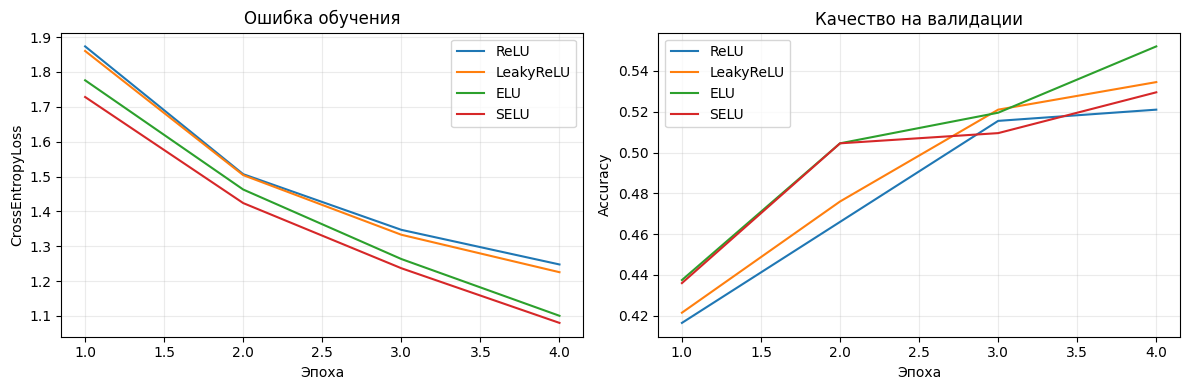

In [4]:
def fit(model, train_data, val_data, epochs=3, lr=0.001):
    torch.manual_seed(SEED)
    loader = DataLoader(train_data, batch_size=128, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    val_loader = DataLoader(val_data, batch_size=256)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = []
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        loss_sum = correct = total = 0
        for x, y in loader:
            optimizer.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
        model.eval()
        vc = vn = 0
        with torch.inference_mode():
            for x, y in val_loader:
                vc += (model(x).argmax(1) == y).sum().item()
                vn += len(y)
        row = (loss_sum / total, correct / total, vc / vn, time.perf_counter()-start)
        history.append(row)
        print(f'Эпоха {epoch+1}: loss={row[0]:.4f}, train={row[1]:.2%}, val={row[2]:.2%}, время={row[3]:.1f} с')
    return np.array(history)

def plot_histories(histories):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, h in histories.items():
        axes[0].plot(np.arange(1,len(h)+1),h[:,0],label=name)
        axes[1].plot(np.arange(1,len(h)+1),h[:,2],label=name)
    axes[0].set(title='Ошибка обучения',xlabel='Эпоха',ylabel='CrossEntropyLoss')
    axes[1].set(title='Качество на валидации',xlabel='Эпоха',ylabel='Accuracy')
    for ax in axes:ax.legend();ax.grid(alpha=.25)
    plt.tight_layout();plt.show()

histories={}
for activation in ['ReLU','LeakyReLU','ELU','SELU']:
    torch.manual_seed(SEED);print('\n'+activation)
    histories[activation]=fit(build_vgg(activation),train_data,val_data,epochs=4)
plot_histories(histories)

## 5. Аугментации, глубина и регуляризация

Сначала сравниваем глубину, затем добавляем аугментации, затем Dropout и BatchNorm. Валидационные преобразования остаются прежними.


3 блока
Эпоха 1: loss=2.0610, train=23.11%, val=32.85%, время=18.2 с
Эпоха 2: loss=1.7671, train=33.80%, val=39.65%, время=36.6 с
Эпоха 3: loss=1.5935, train=41.06%, val=41.90%, время=51.8 с
Эпоха 4: loss=1.4968, train=44.89%, val=45.40%, время=64.4 с

3 блока + аугментации
Эпоха 1: loss=2.1448, train=18.77%, val=26.20%, время=13.3 с
Эпоха 2: loss=1.9187, train=27.99%, val=30.60%, время=26.2 с
Эпоха 3: loss=1.7755, train=33.45%, val=37.55%, время=39.2 с
Эпоха 4: loss=1.6948, train=37.16%, val=39.95%, время=53.2 с

3 блока + аугментации + BN/Dropout
Эпоха 1: loss=2.0468, train=22.31%, val=32.10%, время=20.1 с
Эпоха 2: loss=1.8079, train=31.11%, val=36.00%, время=40.3 с
Эпоха 3: loss=1.6789, train=37.36%, val=44.25%, время=60.5 с
Эпоха 4: loss=1.5848, train=41.15%, val=48.80%, время=81.2 с
ReLU val=52.10%, train-val=+3.04%, время=37.3 с
LeakyReLU val=53.45%, train-val=+2.44%, время=38.6 с
ELU val=55.20%, train-val=+5.75%, время=42.3 с
SELU val=52.95%, train-val=+9.94%, время=41.1 с
3 бл

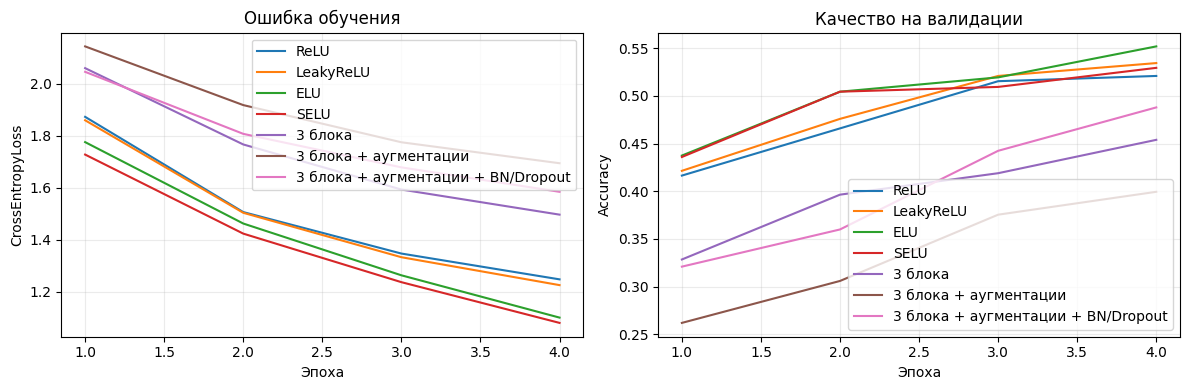

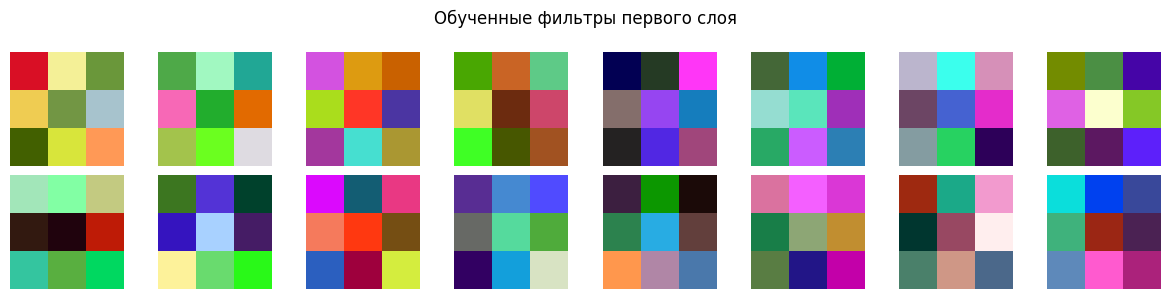

In [5]:
aug_transform=transforms.Compose([transforms.RandomCrop(32,padding=4),transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize((.5,)*3,(.5,)*3)])
aug_raw=datasets.CIFAR10(DATA,train=True,download=False,transform=aug_transform)
aug_train=Subset(aug_raw,tr)
experiments=[('3 блока',False,train_data),('3 блока + аугментации',False,aug_train),('3 блока + аугментации + BN/Dropout',True,aug_train)]
for name,reg,data in experiments:
    torch.manual_seed(SEED);print('\n'+name)
    histories[name]=fit(build_vgg(blocks=3,regularized=reg),data,val_data,epochs=4)
plot_histories(histories)
for name,h in histories.items():print(name,f'val={h[-1,2]:.2%}, train-val={h[-1,1]-h[-1,2]:+.2%}, время={h[-1,3]:.1f} с')
best=max(histories,key=lambda n:histories[n][-1,2]);print('Лучший вариант:',best)
# Визуализация фильтров первого слоя базовой обученной архитектуры.
torch.manual_seed(SEED)
visual_model=build_vgg()
visual_history=fit(visual_model,train_data,val_data,epochs=4)
filters=visual_model[0].weight.detach().numpy()
fig,axes=plt.subplots(2,8,figsize=(12,3))
for ax,w in zip(axes.ravel(),filters):
    w=w.transpose(1,2,0);ax.imshow((w-w.min())/(np.ptp(w)+1e-8));ax.axis('off')
plt.suptitle('Обученные фильтры первого слоя');plt.tight_layout();plt.show()

## Вывод

На фиксированной подвыборке за четыре эпохи лучший результат дала **ELU — 55,20% accuracy** против **52,10% у ReLU**. LeakyReLU получила 53,45%, SELU — 52,95%. ELU уже на первой эпохе дала 43,75% против 41,65% у ReLU, однако обучение заняло 42,3 с вместо 37,3 с.

Три VGG-блока без регуляризации получили 45,40%. С аугментациями — 39,95%, а с добавлением BatchNorm и Dropout — 48,80%. За четыре эпохи более глубокая сеть не обошла простую; аугментациям требуется больше времени обучения. Одного короткого запуска недостаточно для вывода о предельном качестве.

Фильтры первого слоя визуализированы после обучения. Для SELU проверялась только замена активации с общей инициализацией: полноценная самонормализующаяся сеть требует отдельного эксперимента.